In [21]:
import kagglehub
import numpy as np
import os

path = kagglehub.dataset_download("hojjatk/mnist-dataset")

#print("Path to dataset files:", path)

def load_images(file_path):
    with open(file_path, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    return data.reshape(-1, 28, 28)

def load_labels(file_path):
    with open(file_path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

x_train = load_images(os.path.join(path, 'train-images.idx3-ubyte'))
y_train = load_labels(os.path.join(path, 'train-labels.idx1-ubyte'))
x_test  = load_images(os.path.join(path, 't10k-images.idx3-ubyte'))
y_test  = load_labels(os.path.join(path, 't10k-labels.idx1-ubyte'))

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)
print(x_train[0])
print(y_train)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 2

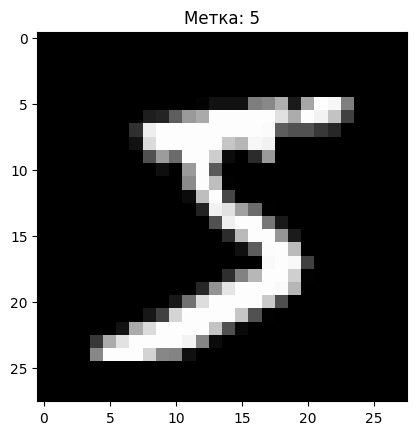

In [22]:
import matplotlib.pyplot as plt

plt.imshow(x_train[0], cmap='gray')
plt.title(f'Метка: {y_train[0]}')
plt.show()

In [23]:
x_train = np.float32(x_train.reshape(-1, 784)) / 255
x_test = np.float32(x_test.reshape(-1, 784)) / 255
#x_train[0]

def to_one_hot(y):
  one_hot = np.zeros((len(y), 10))
  one_hot[np.arange(len(y)), y] = 1
  return one_hot

y_train_oh = to_one_hot(y_train)
y_test_oh = to_one_hot(y_test)


In [24]:
def random_full(n_in=784, s=300, n_out=10):
    w1 = np.random.randn(n_in, s) * np.sqrt(2 / n_in)
    b1 = np.zeros(s)
    w2 = np.random.randn(s, n_out) * np.sqrt(2 / s)
    b2 = np.zeros(n_out)
    return w1, b1, w2, b2

w1, b1, w2, b2 = random_full(n_in=784, s=300, n_out=10)

In [25]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def forward(X, w1, b1, w2, b2):
  z1 = X @ w1 + b1
  relu = np.maximum(0, z1)
  z2 = relu @ w2 + b2
  p = softmax(z2)
  return z1, relu, p

def cross_entropy(p, y_oh):
  B = p.shape[0]
  return -np.sum(y_oh * np.log(p + 1e-12)) / B

z1, relu, p = forward(x_train[:5], w1, b1, w2, b2)

print(p)

[[0.12015413 0.05352901 0.04948605 0.10920798 0.04278791 0.31767082
  0.09030438 0.05791288 0.09535296 0.06359389]
 [0.07138649 0.08790698 0.03746908 0.12549406 0.03364133 0.20768679
  0.13855087 0.08597247 0.12689799 0.08499393]
 [0.10228537 0.15914484 0.06605673 0.13436443 0.07392775 0.15137546
  0.12832552 0.08258986 0.057721   0.04420905]
 [0.13532069 0.12107339 0.10645405 0.10121828 0.04749208 0.19662415
  0.1075243  0.07250651 0.03563045 0.07615611]
 [0.12798059 0.11746162 0.05532093 0.14532054 0.07908767 0.14944975
  0.12742048 0.03772714 0.07410187 0.08612942]]


In [26]:
def backward(X, y_oh, relu, p, w2):
    B = X.shape[0]
    dz2 = (p - y_oh) / B

    dw2 = relu.T @ dz2
    db2 = dz2.sum(axis=0)

    drelu = dz2 @ w2.T
    dz1 = drelu * (relu > 0)

    dw1 = X.T @ dz1
    db1 = dz1.sum(axis=0)
    return dw1, db1, dw2, db2

In [27]:
eps = 1e-5
thr = 1e-6

X = x_train[:5].astype(np.float64)
Y = y_train_oh[:5]
params = [w1.astype(np.float64), b1.astype(np.float64),
          w2.astype(np.float64), b2.astype(np.float64)]
names = ['w1', 'b1', 'w2', 'b2']

def loss_fn():
    z1, relu, p = forward(X, *params)
    return cross_entropy(p, Y)

z1, relu, p = forward(X, *params)
grads = backward(X, Y, relu, p, params[2])

for name, par, g in zip(names, params, grads):
    nz = np.argwhere(np.abs(g) > thr)
    chosen = np.random.choice(len(nz), size=min(5, len(nz)), replace=False)
    for k in chosen:
        idx = tuple(int(i) for i in nz[k])
        old = par[idx]
        par[idx] = old + eps; loss_plus = loss_fn()
        par[idx] = old - eps; loss_minus = loss_fn()
        par[idx] = old
        num = (loss_plus - loss_minus) / (2 * eps)
        rel = abs(num - g[idx]) / max(abs(num) + abs(g[idx]), 1e-8)
        print(f"  {name} {idx} градиент из backward = {g[idx]:.3e}    градиент по определению = {num:.3e}         отн.ошибка={rel:.1e}")

  w1 (267, 261) градиент из backward = -2.615e-03    градиент по определению = -2.615e-03         отн.ошибка=4.2e-09
  w1 (470, 19) градиент из backward = -1.521e-04    градиент по определению = -1.521e-04         отн.ошибка=6.6e-09
  w1 (208, 54) градиент из backward = -3.688e-03    градиент по определению = -3.688e-03         отн.ошибка=3.9e-10
  w1 (596, 247) градиент из backward = 4.312e-03    градиент по определению = 4.312e-03         отн.ошибка=6.0e-10
  w1 (380, 202) градиент из backward = -1.380e-02    градиент по определению = -1.380e-02         отн.ошибка=1.7e-10
  b1 (281,) градиент из backward = -1.628e-02    градиент по определению = -1.628e-02         отн.ошибка=3.9e-10
  b1 (72,) градиент из backward = 1.187e-02    градиент по определению = 1.187e-02         отн.ошибка=3.4e-10
  b1 (185,) градиент из backward = 1.416e-02    градиент по определению = 1.416e-02         отн.ошибка=2.4e-10
  b1 (13,) градиент из backward = -9.111e-03    градиент по определению = -9.111e-03 

In [28]:
import time

def evaluate(X, y, y_oh, w1, b1, w2, b2):
    z1, relu, p = forward(X, w1, b1, w2, b2)
    loss = cross_entropy(p, y_oh)
    acc = (p.argmax(axis=1) == y).mean()
    return loss, acc

def train(x_train, y_train, y_train_oh, lr=0.1, B=32, epochs=20, s=300):
    n = x_train.shape[0]

    w1, b1, w2, b2 = random_full(x_train.shape[1], s, y_train_oh.shape[1])

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        idx = np.random.permutation(n)

        for start in range(0, n, B):
            batch = idx[start:start + B]
            X_b = x_train[batch]
            Y_b = y_train_oh[batch]

            z1, relu, p = forward(X_b, w1, b1, w2, b2)
            dw1, db1, dw2, db2 = backward(X_b, Y_b, relu, p, w2)

            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

        epoch_time = time.time() - t0
        loss, acc = evaluate(x_train, y_train, y_train_oh, w1, b1, w2, b2)
        print(f"Эпоха {epoch:2d} | loss {loss:.4f} | точность {acc*100:.2f}% | {epoch_time:.1f} с")

    return w1, b1, w2, b2

In [29]:
x_train = x_train.astype(np.float32)
y_train_oh = y_train_oh.astype(np.float32)

w1, b1, w2, b2 = train(x_train, y_train, y_train_oh, lr=0.1, B=32, epochs=2)

Эпоха  1 | loss 0.1532 | точность 95.62% | 8.4 с
Эпоха  2 | loss 0.1015 | точность 97.13% | 10.4 с


In [30]:
w1, b1, w2, b2 = train(x_train, y_train, y_train_oh, lr=0.1, B=32, epochs=20)

Эпоха  1 | loss 0.1550 | точность 95.60% | 4.6 с
Эпоха  2 | loss 0.1023 | точность 97.17% | 7.7 с
Эпоха  3 | loss 0.0730 | точность 97.94% | 4.4 с
Эпоха  4 | loss 0.0543 | точность 98.52% | 7.4 с
Эпоха  5 | loss 0.0441 | точность 98.83% | 4.5 с
Эпоха  6 | loss 0.0357 | точность 99.11% | 7.6 с
Эпоха  7 | loss 0.0317 | точность 99.23% | 4.6 с
Эпоха  8 | loss 0.0247 | точность 99.46% | 7.5 с
Эпоха  9 | loss 0.0232 | точность 99.48% | 4.3 с
Эпоха 10 | loss 0.0185 | точность 99.66% | 7.3 с
Эпоха 11 | loss 0.0150 | точность 99.77% | 4.5 с
Эпоха 12 | loss 0.0131 | точность 99.80% | 7.3 с
Эпоха 13 | loss 0.0115 | точность 99.85% | 4.4 с
Эпоха 14 | loss 0.0096 | точность 99.90% | 7.5 с
Эпоха 15 | loss 0.0085 | точность 99.94% | 4.6 с
Эпоха 16 | loss 0.0075 | точность 99.94% | 7.5 с
Эпоха 17 | loss 0.0061 | точность 99.97% | 4.4 с
Эпоха 18 | loss 0.0056 | точность 99.97% | 7.5 с
Эпоха 19 | loss 0.0054 | точность 99.98% | 4.5 с
Эпоха 20 | loss 0.0047 | точность 99.98% | 7.5 с


In [31]:
loss, err = evaluate(x_test, y_test, y_test_oh, w1, b1, w2, b2)
print(f"Тест: loss {loss:.4f} | точность {err*100:.2f}% | ошибка {(1-err)*100:.2f}%")

Тест: loss 0.0583 | точность 98.25% | ошибка 1.75%
